# 01 · Two-step Diebold–Li baseline, USD

The simplest version of the model (README §6.2). Each month's Treasury curve
is summarised by three Nelson–Siegel factors (level, slope, curvature) using
OLS with λ fixed at 0.0609. The factors are then forecast with AR(1)s or a
VAR(1). This notebook checks that the factors mean what they should, measures
how well three factors fit the curve, and runs a first out-of-sample
comparison with the random walk.

Sample: GSW month-end zero yields. Estimation starts in **1985-01** (Diebold
& Li's start, after the Volcker disinflation). Forecast origins run from
**2000-01** (README §7.1). Run `python -m yck fetch --only USD` first.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from yck.model.dns import fit_factors, fit_rmse_bp, fit_dynamics, DL_LAMBDA
from yck.eval.backtest import dns_two_step_forecasts, random_walk_forecasts, rmse_table

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
EST_START, FIRST_ORIGIN = "1985-01-31", "2000-01-31"
y_all = pd.read_parquet(ROOT / "data/processed/curves_USD.parquet")
y = y_all.loc[EST_START:]
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
print(f"{len(y)} months, {y.index[0]:%Y-%m} to {y.index[-1]:%Y-%m}; missing points: {int(y.isna().sum().sum())}")

502 months, 1985-01 to 2026-10; missing points: 0


## 1. Do the factors mean what they should?

Diebold–Li's interpretation: level ≈ the 10y yield, −slope ≈ the 10y–3m
spread, curvature ≈ 2·y(2y) − y(3m) − y(10y). If the estimated factors don't
track these proxies closely, something is wrong upstream.

What matters is co-movement, not scale. The curvature loading peaks at only
about 0.3, so the curvature factor moves about three times as much as its
proxy. Level sits a little above the 10y yield when the curve is steep,
because the slope and curvature loadings are not yet zero at 10 years.

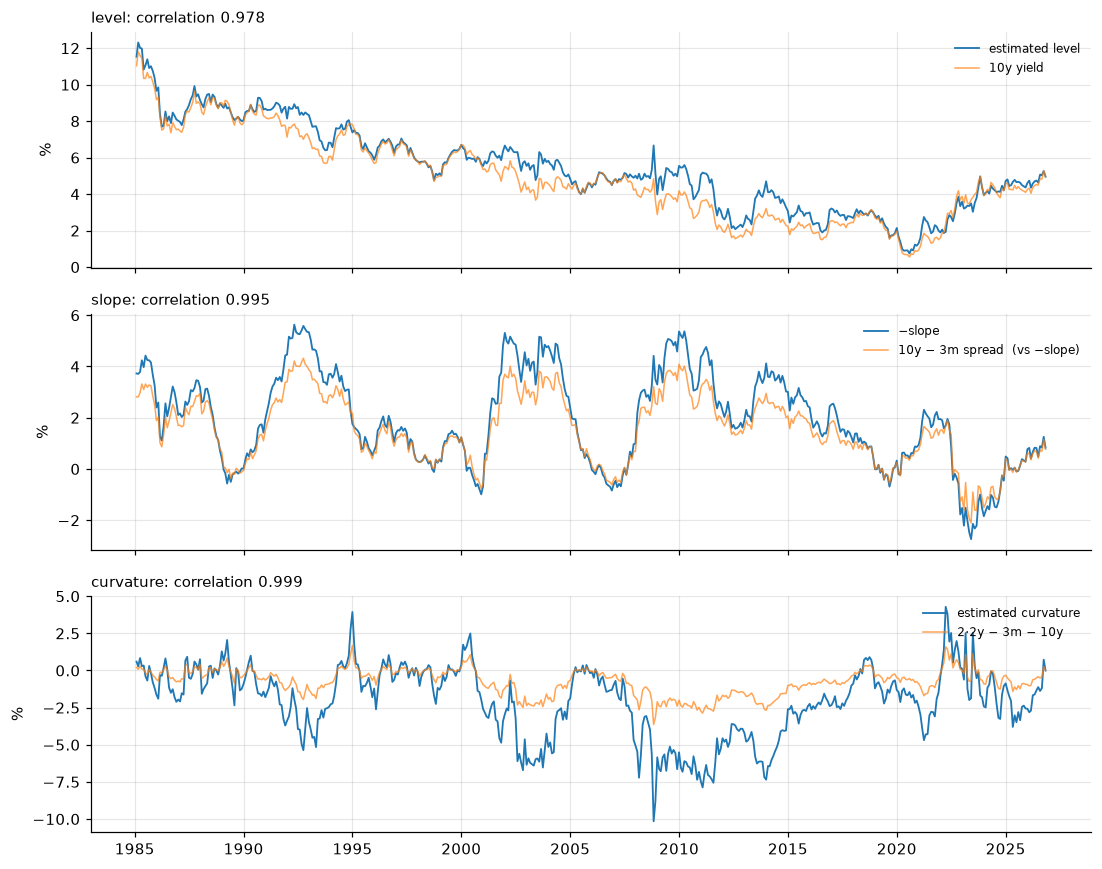

In [2]:
f = fit_factors(y)
proxies = {
    "level": (f.level, y["120m"], "10y yield"),
    "slope": (-f.slope, y["120m"] - y["3m"], "10y − 3m spread  (vs −slope)"),
    "curvature": (f.curvature, 2 * y["24m"] - y["3m"] - y["120m"], "2·2y − 3m − 10y"),
}
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
for ax, (name, (fac, prox, label)) in zip(axes, proxies.items()):
    ax.plot(fac, lw=1.2, label=f"estimated {name}" if name != "slope" else "−slope")
    ax.plot(prox, lw=1, alpha=0.7, label=label)
    ax.set_ylabel("%")
    ax.set_title(f"{name}: correlation {fac.corr(prox):.3f}", loc="left", fontsize=10)
    ax.legend(loc="upper right", fontsize=8, frameon=False)
fig.tight_layout()

## 2. How well do three factors fit the curve?

Cross-sectional RMSE by maturity, in basis points (in-sample). Diebold–Li
report a few bp in the belly and more at the very short end. Here the shape
is the same: the 3m point fits worst, because the fixed λ ties the short-end
loading to the curvature peak, and GSW's sub-1y yields are themselves
extrapolated (README §5.3).

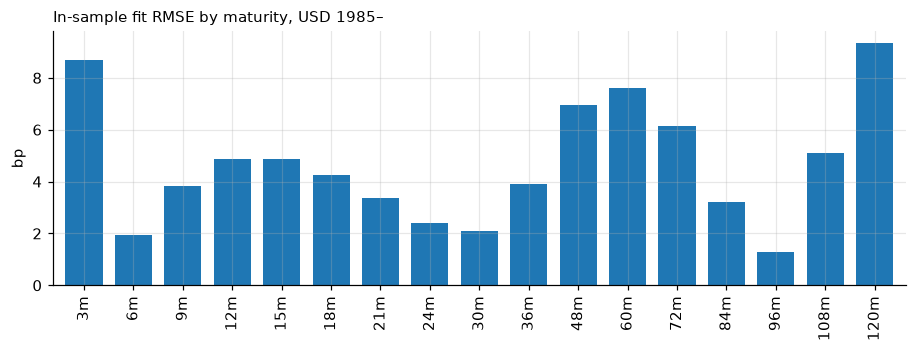

,3m,6m,9m,12m,15m,18m,21m,24m,30m,36m,48m,60m,72m,84m,96m,108m,120m
RMSE (bp),8.7,2.0,3.8,4.9,4.9,4.3,3.4,2.4,2.1,3.9,6.9,7.6,6.1,3.2,1.3,5.1,9.3


In [3]:
rmse = fit_rmse_bp(y, f)
ax = rmse.plot.bar(figsize=(10, 3), color="C0", width=0.75)
ax.set_ylabel("bp"); ax.set_title("In-sample fit RMSE by maturity, USD 1985–", loc="left", fontsize=10)
plt.show()
rmse.round(1).to_frame("RMSE (bp)").T

## 3. Factor dynamics (full sample, for reference)

All three factors are highly persistent: level is close to a unit root and
curvature is the least persistent. The unconditional means μ are the targets
the forecasts revert to, which matters in §5.

In [4]:
rows = {}
for kind in ("ar1", "var1"):
    d = fit_dynamics(f, kind)
    rows[kind.upper()] = {**{f"A[{n}]": a for n, a in zip(("L", "S", "C"), np.diag(d.A))},
                          **{f"mu[{n}]": m for n, m in zip(("L", "S", "C"), d.mu)},
                          "max |eig|": np.max(np.abs(np.linalg.eigvals(d.A)))}
pd.DataFrame(rows).T.round(3)

,A[L],A[S],A[C],mu[L],mu[S],mu[C],max |eig|
AR1,0.984,0.979,0.936,4.587,-1.650,-2.118,0.984
VAR1,0.981,0.934,0.910,4.679,-1.664,-2.160,0.983


## 4. Out-of-sample: does it beat the random walk?

At every month-end origin from 2000-01 the dynamics are re-estimated on data up
to that origin only (expanding window from 1985; the rolling 10-year window
is a robustness check), and the curve is forecast 1, 6 and 12 months ahead.
The benchmark is the random walk, ŷ(t+h) = y(t). All models are scored on the
same targets. **Ratios below 1 mean the model beats the random walk.**

In [5]:
H = (1, 6, 12)
models = {
    "AR(1)": dns_two_step_forecasts(y, H, FIRST_ORIGIN, kind="ar1"),
    "VAR(1)": dns_two_step_forecasts(y, H, FIRST_ORIGIN, kind="var1"),
    "AR(1), 10y window": dns_two_step_forecasts(y, H, FIRST_ORIGIN, kind="ar1", window=120),
    "VAR(1), 10y window": dns_two_step_forecasts(y, H, FIRST_ORIGIN, kind="var1", window=120),
}
rw = random_walk_forecasts(y, H, FIRST_ORIGIN)
SHOW = ["3m", "12m", "24m", "60m", "120m"]

tables = {}
for h in H:
    t = rmse_table({**{n: m[h] for n, m in models.items()}, "RW": rw[h]}, y)
    tables[h] = t
ratio = pd.concat({f"h={h}": tables[h][list(models)].div(tables[h]["RW"], axis=0).loc[SHOW] for h in H}, axis=0)
rwlvl = pd.concat({f"h={h}": tables[h][["RW", "n_obs"]].loc[SHOW] for h in H}, axis=0)
ratio.round(2).join(rwlvl.round(1).rename(columns={"RW": "RW RMSE (bp)"}))

AR(1)  VAR(1)  AR(1), 10y window  VAR(1), 10y window  RW RMSE (bp)  \
h=1  3m     1.08    0.86               1.12                0.87          23.7   
     12m    1.08    0.98               1.07                1.00          21.7   
     24m    1.05    1.00               1.04                1.04          24.6   
     60m    1.14    1.08               1.15                1.14          26.8   
     120m   1.04    1.05               1.03                1.07          26.7   
h=6  3m     1.09    0.84               1.12                0.89          86.5   
     12m    1.14    0.95               1.13                1.05          80.3   
     24m    1.16    1.01               1.13                1.14          76.0   
     60m    1.20    1.08               1.18                1.24          67.0   
     120m   1.08    1.03               1.07                1.18          60.1   
h=12 3m     1.06    0.88               1.08                0.97         149.1   
     12m    1.10    0.96               1.09                1.09         138.9   
     24m    1.15    1.02               1.12                1.19         123.9   
     60m    1.26    1.12               1.20                1.32          95.8   
     120m   1.17    1.07               1.15                1.28          80.2   

           n_obs  
h=1  3m      321  
     12m     321  
     24m     321  
     60m     321  
     120m    321  
h=6  3m      316  
     12m     316  
     24m     316  
     60m     316  
     120m    316  
h=12 3m      310  
     12m     310  
     24m     310  
     60m     310  
     120m    310

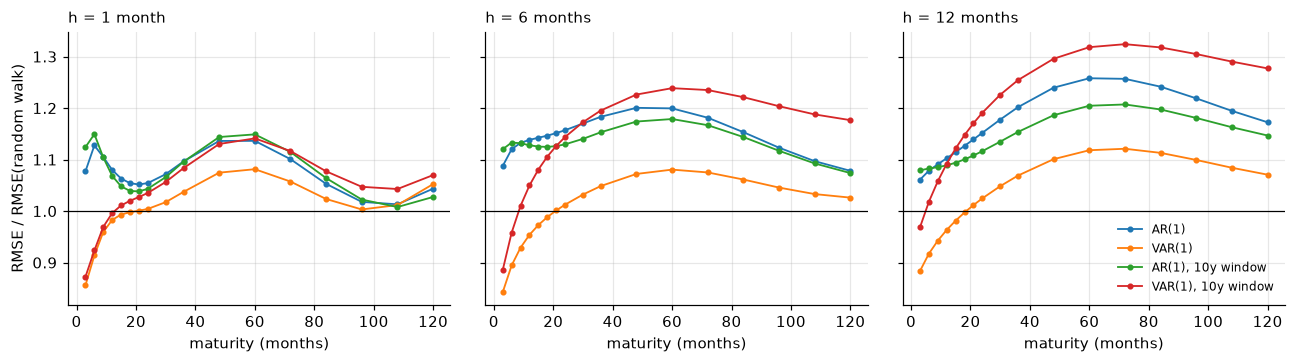

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
mats = [int(c[:-1]) for c in y.columns]
for ax, h in zip(axes, H):
    t = tables[h]
    for n in models:
        ax.plot(mats, t[n] / t["RW"], marker="o", ms=3, lw=1.2, label=n)
    ax.axhline(1, color="k", lw=0.8)
    ax.set_title(f"h = {h} month" + ("s" if h > 1 else ""), loc="left", fontsize=10); ax.set_xlabel("maturity (months)")
axes[0].set_ylabel("RMSE / RMSE(random walk)")
axes[-1].legend(fontsize=8, frameon=False)
fig.tight_layout()

## 5. Why the AR(1) loses: mean-reversion bias

The DNS forecast is μ + Aʰ(f_t − μ), so it always pulls toward the
estimation-sample mean. Since 1985, US rates have trended down and spent
years at the zero lower bound, so a mean estimated on a high-rate history
pushes forecasts **up**. The mean forecast error (forecast − actual) at h = 12
shows this directly. A random walk has no such pull.

In [7]:
h = 12
err = {n: 100 * (m[h] - y).reindex(rw[h].index) for n, m in models.items()}
err["RW"] = 100 * (rw[h] - y).reindex(rw[h].index)
periods = [("2000", "2007", "2000–07"), ("2008", "2015", "2008–15 (ZLB)"), ("2016", "2026", "2016–")]
bias = pd.DataFrame({lab: {n: e.loc[a:b, "120m"].mean() for n, e in err.items()} for a, b, lab in periods})
print("Mean 12-month-ahead forecast error at 10y, bp (positive = forecast too high)")
bias.round(0)

Mean 12-month-ahead forecast error at 10y, bp (positive = forecast too high)


,2000–07,2008–15 (ZLB),2016–
AR(1),58.0,80.0,-10.0
VAR(1),47.0,45.0,11.0
"AR(1), 10y window",53.0,80.0,-24.0
"VAR(1), 10y window",62.0,73.0,-18.0
RW,20.0,31.0,-22.0


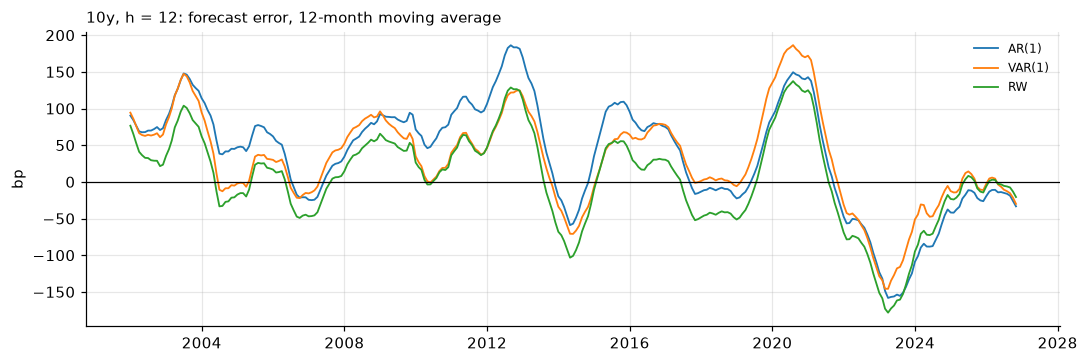

In [8]:
fig, ax = plt.subplots(figsize=(10, 3.4))
for n in ("AR(1)", "VAR(1)", "RW"):
    ax.plot(err[n]["120m"].rolling(12).mean(), lw=1.2, label=n)
ax.axhline(0, color="k", lw=0.8)
ax.set_ylabel("bp"); ax.legend(fontsize=8, frameon=False)
ax.set_title("10y, h = 12: forecast error, 12-month moving average", loc="left", fontsize=10)
fig.tight_layout()

## 6. Takeaways

- **The factors are right.** Level, slope and curvature track their empirical
  proxies with correlations of 0.97–0.999, and three factors fit the curve to a
  few bp, worst at 3m. Step 1 is behaving as in Diebold–Li.
- **The AR(1) does not beat the random walk after 2000.** It is worse at every
  maturity and horizon. This matches the post-2000 literature: DL's strong
  1994–2000 results were partly period-specific.
- **The VAR(1) beats the random walk at the short end** (3m–12m, about
  5–15% lower RMSE at h = 6, 12), presumably because the cross-factor terms
  let the slope inform the level. It still loses at 5–10y.
- **The main failure is bias, not noise.** Forecasts pull toward a
  high-rate historical mean in a falling-rate, zero-lower-bound period.
  A rolling 10y window does not fix it.
- **Next steps.** The one-step Kalman model (§6.3) estimates the same model
  efficiently and handles missing data properly. The macro model (§6.4)
  then tests whether the policy rate and inflation can tell the
  model *when* rates should not revert. These are the baselines it must beat:
  the random walk, and the yields-only DNS (Clark–West, §7.2).